In [3]:
import numpy as np
import pandas as pd
import os, sys, re
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from pathlib import Path
import glob


In [4]:
current_dir = os.getcwd()
CONDITIONS_FILE = os.path.abspath(os.path.join(current_dir, "../data/sub_conditions.csv"))
DATA_DIR        = os.path.abspath(os.path.join(current_dir, "../data/02_processed_combined_data"))

In [40]:
def parse_subject_id(respondent_name):
    """
    Extracts subject ID (e.g., 'sub001') from RespondentName string.
    Handles potential extra spaces or underscores.
    """
    # Split by underscore and take the first part
    parts = respondent_name.split('_')
    sub_id = parts[0].strip()
    return sub_id
    
def get_subjects_by_condition(conditions_file, target_condition='PC'):
    """
    Reads the conditions file and returns a list of subject IDs for the target condition.
    """
    if not os.path.exists(conditions_file):
        raise FileNotFoundError(f"Conditions file not found: {conditions_file}")
        
    df = pd.read_csv(conditions_file)
    
    # Clean column names just in case
    df.columns = [c.strip() for c in df.columns]
    
    if 'RespondentName' not in df.columns or 'SourceStimulus' not in df.columns:
        raise ValueError("Conditions file must contain 'RespondentName' and 'SourceStimulus' columns.")
    
    # Filter by condition
    condition_df = df[df['SourceStimulus'].str.strip() == target_condition].copy()
    
    subject_ids = condition_df['RespondentName'].apply(parse_subject_id).tolist()
    
    # Remove duplicates if any
    subject_ids = sorted(list(set(subject_ids)))
    
    #print(f"[{target_condition}] Found {len(subject_ids)} subjects in condition file.")
    return subject_ids

import pandas as pd
import glob
import os

def load_filtered_physiological_data(folder_path, subject_list):
    """
    Loads CSV files ONLY if they match an ID in subject_list.
    Checks for required columns and data integrity.
    Returns a dictionary of DataFrames (Time x Subjects).
    """
    
    required_cols = ['Time_sec', 'GSR', 'Heart_Rate', 'Pupil_Mean', 'Gaze_X', 'Gaze_Y']
    signal_types = ['GSR', 'Heart_Rate', 'Pupil_Mean', 'Gaze_X', 'Gaze_Y']
    
    # 1. Structure to hold data: {'GSR': [], 'Heart_Rate': [], ...}
    data_collector = {signal: [] for signal in signal_types}
    
    file_list = glob.glob(os.path.join(folder_path, "*.csv"))
    
    print(f"Scanning {len(file_list)} files against {len(subject_list)} subject IDs...")
    
    loaded_count = 0
    
    for filepath in file_list:
        filename = os.path.basename(filepath)
        
        # --- FILTER 1: CHECK FILENAME AGAINST LIST ---
        # We look for a subject ID that exists inside this filename.
        # e.g., if filename is 'sub003_combined_physio.csv' and 'sub003' is in the list
        matched_subject_id = None
        
        for subj_id in subject_list:
            if subj_id in filename:
                matched_subject_id = subj_id
                break # Found the match, stop checking other IDs
        
        # If this file doesn't match anyone in our list, skip it silently
        if matched_subject_id is None:
            continue

        try:
            # Load data
            df = pd.read_csv(filepath)
            
            # --- FILTER 2: CHECK COLUMN EXISTENCE ---
            if not set(required_cols).issubset(df.columns):
                print(f"Skipping {matched_subject_id} (File: {filename}) - Missing required columns")
                continue
            
            # --- FILTER 3: CHECK FOR EMPTY/NAN DATA ---
            # Check if any required column has NaN values
            if df[required_cols].isnull().any().any():
                print(f"Skipping {matched_subject_id} (File: {filename}) - Contains NaNs/Missing data")
                continue
                
            # --- PROCESSING ---
            # 1. Handle Time Index (Round to 3 decimals to ensure alignment across subjects)
            df['Time_sec'] = df['Time_sec'].round(3)
            df = df.set_index('Time_sec')
            
            # 2. Add each signal to its respective list
            for signal in signal_types:
                s = df[signal]
                s.name = matched_subject_id  # Column name becomes 'sub002', etc.
                data_collector[signal].append(s)
                
            loaded_count += 1
            
        except Exception as e:
            print(f"Error reading {filename}: {e}")

    print(f"Successfully loaded {loaded_count} valid subjects.")

    # --- MERGING ---
    final_dfs = {}
    for signal, series_list in data_collector.items():
        if series_list:
            # Concat aligns on the Index (Time_sec) automatically
            merged_df = pd.concat(series_list, axis=1)
            merged_df.sort_index(inplace=True)
            final_dfs[signal] = merged_df
        else:
            final_dfs[signal] = pd.DataFrame()

    return final_dfs

def plot_split_half_comparison(data_df, title="Split-Half Consistency", output_path=None):
    """
    Visualizes two random halves of the group to show consistency.
    """
    data = data_df.values
    n_subjects = data.shape[1]
    indices = np.arange(n_subjects)
    np.random.shuffle(indices)
    mid = n_subjects // 2
    
    g1 = data[:, indices[:mid]].mean(axis=1)
    g2 = data[:, indices[mid:]].mean(axis=1)
    
    plt.figure(figsize=(5, 2))
    plt.plot(g1, color='dodgerblue', alpha=0.9, linewidth=1.5, label='Split Group 1')
    plt.plot(g2, color='darkorange', alpha=0.9, linewidth=1.5, label='Split Group 2')
    
    # Correlation between them
    r = np.corrcoef(g1, g2)[0, 1]
    
    plt.title(f"{title} (r = {r:.3f})")
    plt.xlabel("Time (samples)")
    plt.ylabel("Signal Amplitude")
    #plt.legend()
    plt.xlim(0, len(g1))
    plt.yticks([]) 

    sns.despine()
    
    plt.tight_layout()
    if output_path:
        plt.savefig(output_path, dpi=300)
        print(f"Split-half plot saved to {output_path}")
    plt.show()
    #plt.close()

In [41]:
pc_subjs = get_subjects_by_condition(CONDITIONS_FILE, target_condition='PC') 

results = load_filtered_physiological_data(DATA_DIR, pc_subjs)
results
# # Access specific DataFrames
gsr_data = results['GSR'] 
hr_data = results['Heart_Rate']
pupil_data = results['Pupil_Mean']
gazeX_data = results['Gaze_X']
gazeY_data = results['Gaze_Y']


print(gsr_data.shape)
print(hr_data.shape)
print(pupil_data.shape)
print(gazeX_data.shape)
print(gazeY_data.shape)


Scanning 194 files against 99 subject IDs...
Successfully loaded 97 valid subjects.
(6381, 97)
(6381, 97)
(6381, 97)
(6381, 97)
(6381, 97)


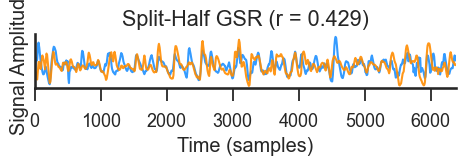

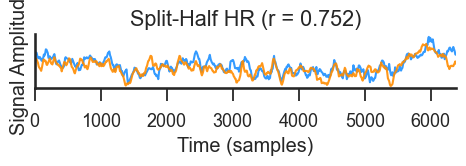

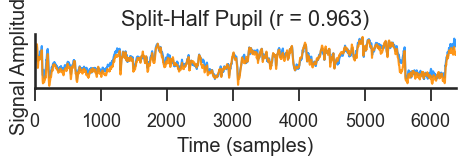

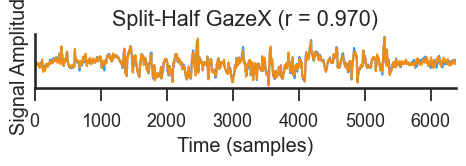

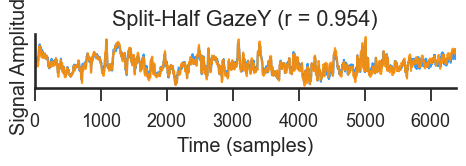

In [73]:
plot_split_half_comparison(gsr_data, title="Split-Half GSR")
plot_split_half_comparison(hr_data, title="Split-Half HR")
plot_split_half_comparison(pupil_data, title="Split-Half Pupil")
plot_split_half_comparison(gazeX_data, title="Split-Half GazeX")
plot_split_half_comparison(gazeY_data, title="Split-Half GazeY")

In [45]:
from nltools.stats import isc, threshold, fdr


ISC: 0.026, p = 0.002


/Users/schmaelz/miniconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


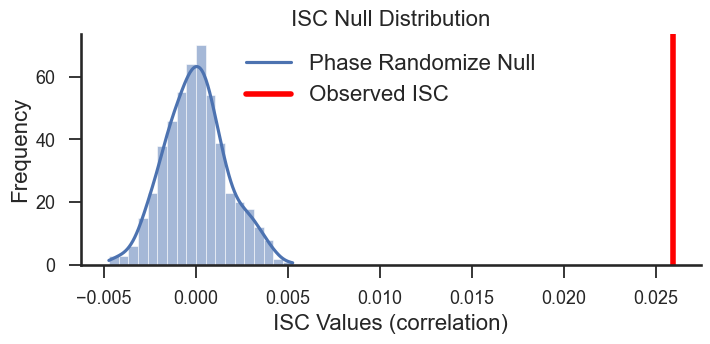

In [65]:
stats_phase = isc(gsr_data, method='phase_randomize', n_samples=500, return_null=True)
print(f"ISC: {stats_phase['isc']:.02}, p = {stats_phase['p']:.03}")

fs = 16

sns.set(style="ticks", context="talk")
plt.style.use("seaborn-v0_8-talk")

plt.figure(figsize=(8,3));

sns.histplot(stats_phase['null_distribution'], kde=True, label='Bootstrap');
plt.ylabel('Frequency', fontsize= fs);
plt.xlabel('ISC Values (correlation)', fontsize= fs);
plt.title('ISC Null Distribution', fontsize= fs);
plt.axvline(stats_phase['isc'], linestyle='-', color='red', linewidth=4);
plt.legend(['Phase Randomize Null', 'Observed ISC'], fontsize=fs);
sns.despine()    
plt.show()

ISC: 0.11, p = 0.002


/Users/schmaelz/miniconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


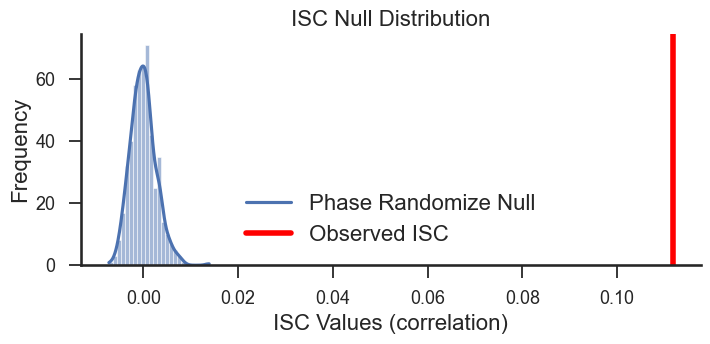

In [68]:
stats_phase = isc(hr_data, method='phase_randomize', n_samples=500, return_null=True)
print(f"ISC: {stats_phase['isc']:.02}, p = {stats_phase['p']:.03}")

fs = 16

sns.set(style="ticks", context="talk")
plt.style.use("seaborn-v0_8-talk")

plt.figure(figsize=(8,3));

sns.histplot(stats_phase['null_distribution'], kde=True, label='Bootstrap');
plt.ylabel('Frequency', fontsize= fs);
plt.xlabel('ISC Values (correlation)', fontsize= fs);
plt.title('ISC Null Distribution', fontsize= fs);
plt.axvline(stats_phase['isc'], linestyle='-', color='red', linewidth=4);
plt.legend(['Phase Randomize Null', 'Observed ISC'], fontsize=fs);
sns.despine()    
plt.show()

ISC: 0.5, p = 0.002


/Users/schmaelz/miniconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


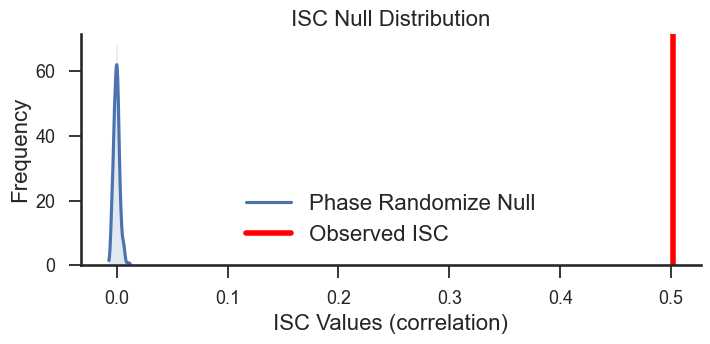

In [69]:
stats_phase = isc(pupil_data, method='phase_randomize', n_samples=500, return_null=True)
print(f"ISC: {stats_phase['isc']:.02}, p = {stats_phase['p']:.03}")

fs = 16

sns.set(style="ticks", context="talk")
plt.style.use("seaborn-v0_8-talk")

plt.figure(figsize=(8,3));

sns.histplot(stats_phase['null_distribution'], kde=True, label='Bootstrap');
plt.ylabel('Frequency', fontsize= fs);
plt.xlabel('ISC Values (correlation)', fontsize= fs);
plt.title('ISC Null Distribution', fontsize= fs);
plt.axvline(stats_phase['isc'], linestyle='-', color='red', linewidth=4);
plt.legend(['Phase Randomize Null', 'Observed ISC'], fontsize=fs);
sns.despine()    
plt.show()

ISC: 0.43, p = 0.002


/Users/schmaelz/miniconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


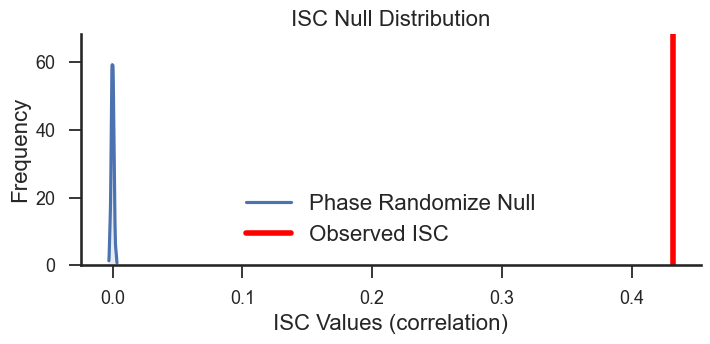

In [67]:
stats_phase = isc(gazeX_data, method='phase_randomize', n_samples=500, return_null=True)
print(f"ISC: {stats_phase['isc']:.02}, p = {stats_phase['p']:.03}")

fs = 16

sns.set(style="ticks", context="talk")
plt.style.use("seaborn-v0_8-talk")

plt.figure(figsize=(8,3));

sns.histplot(stats_phase['null_distribution'], kde=True, label='Bootstrap');
plt.ylabel('Frequency', fontsize= fs);
plt.xlabel('ISC Values (correlation)', fontsize= fs);
plt.title('ISC Null Distribution', fontsize= fs);
plt.axvline(stats_phase['isc'], linestyle='-', color='red', linewidth=4);
plt.legend(['Phase Randomize Null', 'Observed ISC'], fontsize=fs);
sns.despine()    
plt.show()

ISC: 0.31, p = 0.002


/Users/schmaelz/miniconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


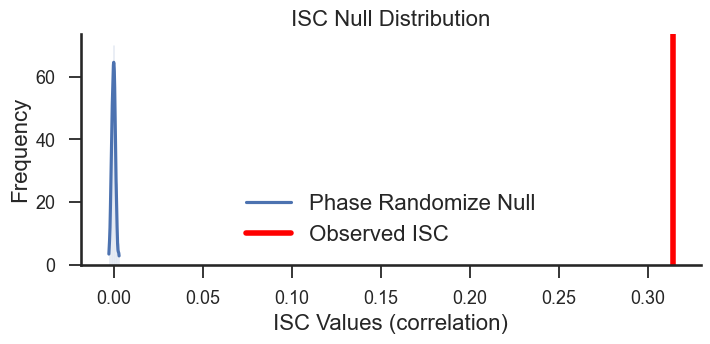

In [70]:
stats_phase = isc(gazeY_data, method='phase_randomize', n_samples=500, return_null=True)
print(f"ISC: {stats_phase['isc']:.02}, p = {stats_phase['p']:.03}")

fs = 16

sns.set(style="ticks", context="talk")
plt.style.use("seaborn-v0_8-talk")

plt.figure(figsize=(8,3));

sns.histplot(stats_phase['null_distribution'], kde=True, label='Bootstrap');
plt.ylabel('Frequency', fontsize= fs);
plt.xlabel('ISC Values (correlation)', fontsize= fs);
plt.title('ISC Null Distribution', fontsize= fs);
plt.axvline(stats_phase['isc'], linestyle='-', color='red', linewidth=4);
plt.legend(['Phase Randomize Null', 'Observed ISC'], fontsize=fs);
sns.despine()    
plt.show()